# Proyek Analisis Data: [Bike Sharing Dataset]
- **Nama:** Yohanes Pratama
- **Email:** yohanespratama05gmail.com
- **ID Dicoding:** yohanes_pratamarih4

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".


- **Pertanyaan 1:** Pada jam berapakah rata-rata penyewaan sepeda mencapai titik tertinggi pada hari kerja dibandingkan dengan hari libur/akhir pekan?
- **Pertanyaan 2:** Bagaimana perbandingan tren rata-rata penyewaan sepeda per jam di setiap musim antara pengguna kasual dan pengguna terdaftar?

## Import Semua Packages/Library yang Digunakan

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## Data Wrangling

### Gathering Data

#### Load Bike Sharing Data


In [2]:
df = pd.read_csv('hour.csv')
display(df.head())

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


**Insight:**
- Dataset berhasil dimuat dan berisi data penyewaan sepeda per jam dengan 17.379 baris dan 17 kolom.
- Kolom-kolom kunci meliputi waktu (`dteday`, `hr`), kondisi musim/cuaca (`season`, `weathersit`), serta jumlah penyewa (`casual`, `registered`, `cnt`).


### Assessing Data

#### Menilai Struktur dan Kualitas Data (Assessing Data)


In [3]:
print("=== Info Dataset ===")
print(df.info())
print("\n=== Statistik Deskriptif ===")
display(df.describe())
print("\n=== Jumlah Duplikasi ===")
print(df.duplicated().sum())
print("\n=== Jumlah Missing Values ===")
print(df.isnull().sum())

=== Info Dataset ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     17379 non-null  int64  
 1   dteday      17379 non-null  object 
 2   season      17379 non-null  int64  
 3   yr          17379 non-null  int64  
 4   mnth        17379 non-null  int64  
 5   hr          17379 non-null  int64  
 6   holiday     17379 non-null  int64  
 7   weekday     17379 non-null  int64  
 8   workingday  17379 non-null  int64  
 9   weathersit  17379 non-null  int64  
 10  temp        17379 non-null  float64
 11  atemp       17379 non-null  float64
 12  hum         17379 non-null  float64
 13  windspeed   17379 non-null  float64
 14  casual      17379 non-null  int64  
 15  registered  17379 non-null  int64  
 16  cnt         17379 non-null  int64  
dtypes: float64(4), int64(12), object(1)
memory usage: 2.3+ MB
None

=== Statistik Deskript

,instant,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,17379.0000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000
mean,8690.0000,2.501640,0.502561,6.537775,11.546752,0.028770,3.003683,0.682721,1.425283,0.496987,0.475775,0.627229,0.190098,35.676218,153.786869,189.463088
std,5017.0295,1.106918,0.500008,3.438776,6.914405,0.167165,2.005771,0.465431,0.639357,0.192556,0.171850,0.192930,0.122340,49.305030,151.357286,181.387599
min,1.0000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.020000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,4345.5000,2.000000,0.000000,4.000000,6.000000,0.000000,1.000000,0.000000,1.000000,0.340000,0.333300,0.480000,0.104500,4.000000,34.000000,40.000000
50%,8690.0000,3.000000,1.000000,7.000000,12.000000,0.000000,3.000000,1.000000,1.000000,0.500000,0.484800,0.630000,0.194000,17.000000,115.000000,142.000000
75%,13034.5000,3.000000,1.000000,10.000000,18.000000,0.000000,5.000000,1.000000,2.000000,0.660000,0.621200,0.780000,0.253700,48.000000,220.000000,281.000000
max,17379.0000,4.000000,1.000000,12.000000,23.000000,1.000000,6.000000,1.000000,4.000000,1.000000,1.000000,1.000000,0.850700,367.000000,886.000000,977.000000



=== Jumlah Duplikasi ===
0

=== Jumlah Missing Values ===
instant       0
dteday        0
season        0
yr            0
mnth          0
hr            0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
dtype: int64


**Steps to Take:**
- Mengonversi tipe data kolom `dteday` dari object menjadi datetime.
- Mengubah nilai kategori pada kolom `season`, `weathersit`, dan `workingday` agar lebih mudah dipahami dalam proses visualisasi.
- Memastikan tidak ada data yang hilang (missing values) atau duplikasi.

**Insight:**
- Tidak ditemukan missing values maupun data duplikat.
- Tipe data `dteday` masih berupa object (string) dan perlu diubah menjadi format datetime.


### Cleaning Data

#### Membersihkan dan Mentransformasi Data (Cleaning Data)

In [4]:
df = df.drop_duplicates()

df = df.dropna(how='all')

# Konversi tipe data dteday ke datetime
df['dteday'] = pd.to_datetime(df['dteday'])

# Mapping kategori
season_mapping = {1: 'Spring', 2: 'Summer', 3: 'Fall', 4: 'Winter'}
df['season_label'] = df['season'].map(season_mapping)

weather_mapping = {
    1: 'Clear/Partly Cloudy',
    2: 'Misty/Cloudy',
    3: 'Light Snow/Rain',
    4: 'Heavy Rain/Ice Pallets'
}
df['weather_label'] = df['weathersit'].map(weather_mapping)

workingday_mapping = {0: 'Weekend/Holiday', 1: 'Working Day'}
df['day_type'] = df['workingday'].map(workingday_mapping)

print("=== Info Dataset Setelah Pembersihan ===")
print(df.info())
display(df.head())

=== Info Dataset Setelah Pembersihan ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 20 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   instant        17379 non-null  int64         
 1   dteday         17379 non-null  datetime64[ns]
 2   season         17379 non-null  int64         
 3   yr             17379 non-null  int64         
 4   mnth           17379 non-null  int64         
 5   hr             17379 non-null  int64         
 6   holiday        17379 non-null  int64         
 7   weekday        17379 non-null  int64         
 8   workingday     17379 non-null  int64         
 9   weathersit     17379 non-null  int64         
 10  temp           17379 non-null  float64       
 11  atemp          17379 non-null  float64       
 12  hum            17379 non-null  float64       
 13  windspeed      17379 non-null  float64       
 14  casual         17379 non-null

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt,season_label,weather_label,day_type
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16,Spring,Clear/Partly Cloudy,Weekend/Holiday
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40,Spring,Clear/Partly Cloudy,Weekend/Holiday
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32,Spring,Clear/Partly Cloudy,Weekend/Holiday
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13,Spring,Clear/Partly Cloudy,Weekend/Holiday
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1,Spring,Clear/Partly Cloudy,Weekend/Holiday


**Insight:**
- Kolom `dteday` kini bertipe datetime.
- Kolom baru `season_label`, `weather_label`, dan `day_type` telah ditambahkan untuk mempermudah interpretasi grafik pada tahap visualisasi.
- Tidak ditemukan missing value dan missing data pada dataset yang digunakan ini.

## Exploratory Data Analysis (EDA)

### Eksplorasi Hubungan Variabel dan Pola Penyewaan

In [5]:
hourly_day_type = df.groupby(['hr', 'day_type'])['cnt'].mean().reset_index()
display(hourly_day_type.head())

seasonal_users = df.groupby('season_label')[['casual', 'registered']].mean().reset_index()
display(seasonal_users)

weather_impact = df.groupby('weather_label')['cnt'].mean().reset_index()
display(weather_impact)

,hr,day_type,cnt
0,0,Weekend/Holiday,90.800000
1,0,Working Day,36.786290
2,1,Weekend/Holiday,69.508696
3,1,Working Day,16.552632
4,2,Weekend/Holiday,53.171053


,season_label,casual,registered
0,Fall,50.287144,185.729093
1,Spring,14.290901,96.823668
2,Summer,46.160581,162.183488
3,Winter,30.666824,168.202032


,weather_label,cnt
0,Clear/Partly Cloudy,204.869272
1,Heavy Rain/Ice Pallets,74.333333
2,Light Snow/Rain,111.579281
3,Misty/Cloudy,175.165493


**Insight:**
- Pada hari kerja, terdapat lonjakan penyewaan yang sangat signifikan pada jam sibuk (07:00-08:00 dan 17:00-18:00).
- Pada hari libur/akhir pekan, pola penyewaan cenderung terdistribusi merata di siang hari dari jam 10:00 hingga 16:00.
- Pengguna terdaftar (`registered`) mendominasi jumlah penyewaan di setiap musim dibandingkan pengguna kasual (`casual`).
- Cuaca yang buruk menurunkan tingkat penyewaan secara drastis.

## Visualization & Explanatory Analysis

### Pertanyaan 1:

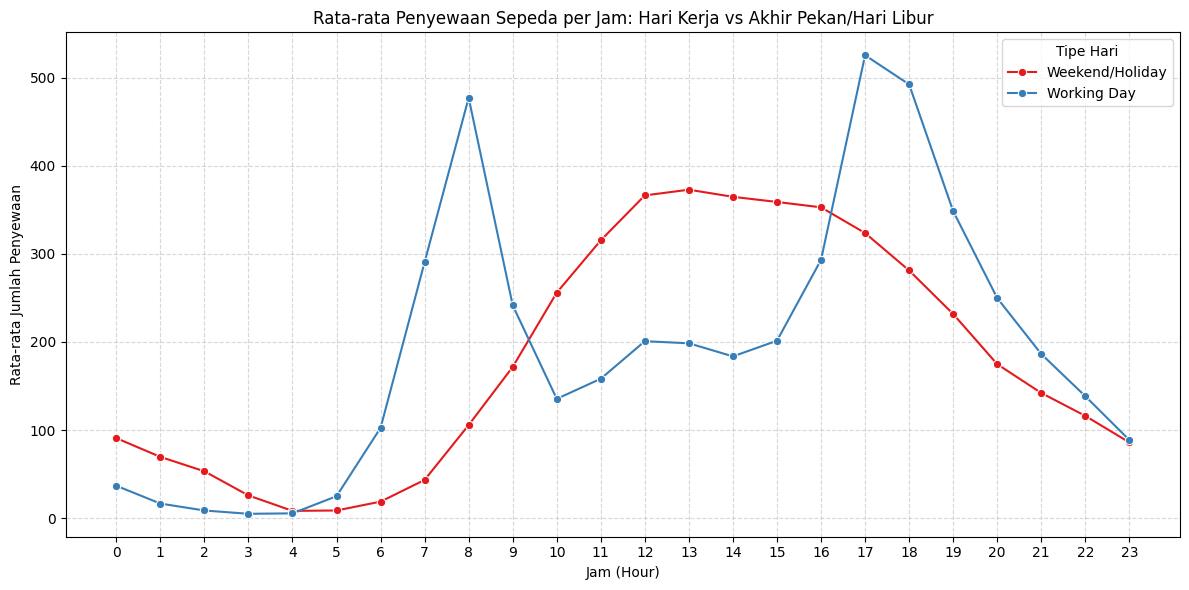

In [6]:
plt.figure(figsize=(12, 6))
sns.lineplot(data=hourly_day_type, x='hr', y='cnt', hue='day_type', marker='o', palette='Set1')
plt.title('Rata-rata Penyewaan Sepeda per Jam: Hari Kerja vs Akhir Pekan/Hari Libur')
plt.xlabel('Jam (Hour)')
plt.ylabel('Rata-rata Jumlah Penyewaan')
plt.xticks(range(0, 24))
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(title='Tipe Hari')
plt.tight_layout()
plt.show()

### Pertanyaan 2:

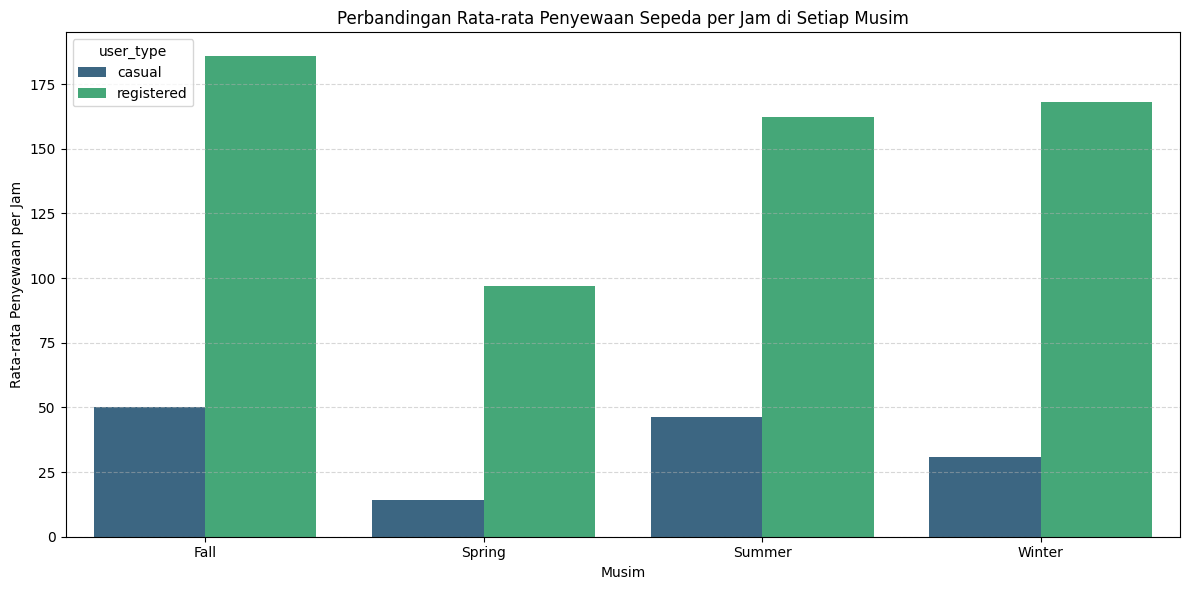

In [7]:
seasonal_melted = seasonal_users.melt(id_vars='season_label', value_vars=['casual', 'registered'],
                                      var_name='user_type', value_name='avg_rentals')

plt.figure(figsize=(12, 6))
sns.barplot(data=seasonal_melted, x='season_label', y='avg_rentals', hue='user_type', palette='viridis')
plt.title('Perbandingan Rata-rata Penyewaan Sepeda per Jam di Setiap Musim')
plt.xlabel('Musim')
plt.ylabel('Rata-rata Penyewaan per Jam')
plt.grid(True, axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

## Analisis Lanjutan (Opsional)

/tmp/ipykernel_696/509072922.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


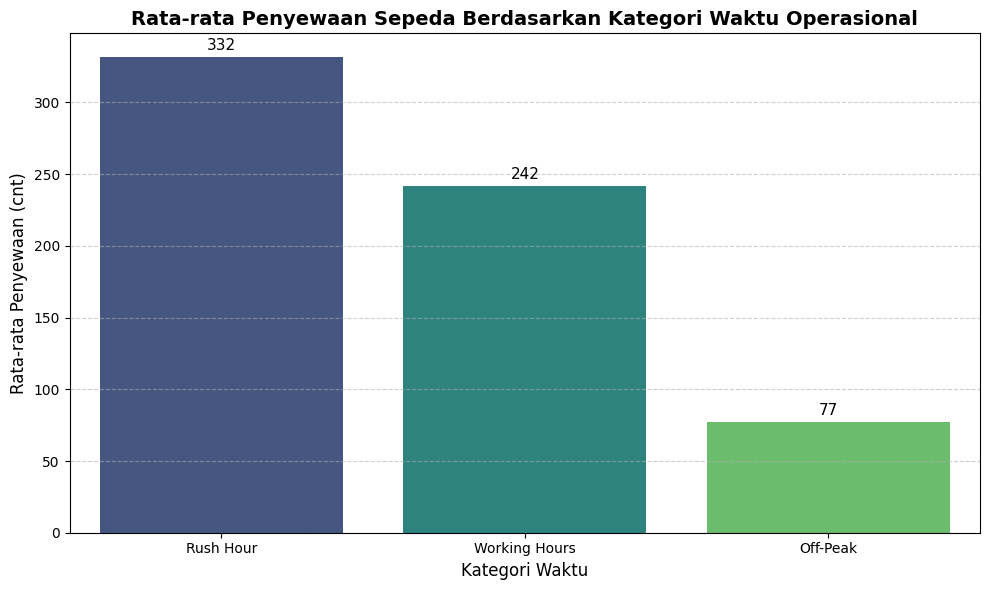

In [9]:
def get_time_category(hour):
    if (7 <= hour <= 9) or (17 <= hour <= 19):
        return 'Rush Hour'
    elif 10 <= hour <= 16:
        return 'Working Hours'
    else:
        return 'Off-Peak'

df['time_category'] = df['hr'].apply(get_time_category)

cluster_time_result = df.groupby('time_category')['cnt'].mean().reset_index()

cluster_time_result_sorted = cluster_time_result.sort_values(by='cnt', ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(
    data=cluster_time_result_sorted,
    x='time_category',
    y='cnt',
    palette='viridis'
)

plt.title('Rata-rata Penyewaan Sepeda Berdasarkan Kategori Waktu Operasional', fontsize=14, fontweight='bold')
plt.xlabel('Kategori Waktu', fontsize=12)
plt.ylabel('Rata-rata Penyewaan (cnt)', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.6)

for index, row in enumerate(cluster_time_result_sorted['cnt']):
    plt.text(index, row + 5, f'{row:.0f}', color='black', ha="center", fontsize=11)

plt.tight_layout()
plt.show()

**Insight:**
- Pengelompokan waktu menunjukkan bahwa rata-rata penyewaan tertinggi terjadi pada "Rush Hour" (07:00-09:00 dan 17:00-19:00).

- Penyewaan berada pada tingkat moderat selama "Working Hours" (10:00-16:00), dan turun drastis pada waktu "Off-Peak" (malam hingga dini hari).

## Conclusion & Recommendation

- **Conclusion pertanyaan 1:** Pada hari kerja, puncak penyewaan sepeda terjadi pada jam masuk kantor (07:00 - 08:00) dan pulang kantor (17:00 - 18:00). Sebaliknya, pada akhir pekan atau hari libur, aktivitas penyewaan memuncak pada siang hingga sore hari (12:00 - 15:00) yang didominasi oleh aktivitas rekreasi.
- **Conclusion pertanyaan 2:** Pengguna terdaftar (`registered`) menunjukkan tren penggunaan yang konsisten dan tinggi di setiap musim dengan aktivitas tertinggi terjadi pada musim gugur (Fall). Pengguna kasual (`casual`) juga mencatatkan penyewaan tertinggi di musim gugur, namun volumenya selalu berada jauh di bawah pengguna terdaftar.

**Rekomendasi Action Item:**
- **Manajemen Armada:** Memperbanyak ketersediaan sepeda di stasiun terdekat area perkantoran pada jam sibuk hari kerja (07:00 - 09:00 dan 17:00 - 19:00).
- **Promosi Musiman:** Memberikan promo khusus atau paket berlangganan bagi pengguna kasual selama musim gugur (Fall) dan musim panas (Summer) untuk mendorong konversi menjadi pengguna terdaftar.